# Розвідувальний аналіз даних для прогнозування цукрового діабету

**Мета:** перевірити структуру набору даних, візуалізувати основні ознаки, дослідити дисбаланс класів і підготувати графіки для підрозділу 3.2 магістерської роботи.

Це описовий аналіз, а не клінічна діагностика. Зв’язок ознак із міткою класу не доводить причинність. Моделі в цьому ноутбуці не навчаються.

## 1. Підготовка середовища

Розмісти цей файл у папці `da` поруч із `diabetes_prediction_dataset.csv`. Якщо є лише ZIP, ноутбук автоматично знайде файл `diabetes_prediction_dataset.csv (1).zip`. Результати зберігатимуться в `results/figures` та `results/tables`.

In [1]:
from pathlib import Path
import zipfile
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('Робоча папка:', Path.cwd())

Python: 3.12.5
pandas: 3.0.6
numpy: 2.5.4
Робоча папка: /Users/glebsavelev/Desktop/da


In [2]:
ROOT = Path.cwd()
CSV_PATH = ROOT / 'diabetes_prediction_dataset.csv'
ZIP_PATH = ROOT / 'diabetes_prediction_dataset.csv (1).zip'
FIGURES = ROOT / 'results' / 'figures'
TABLES = ROOT / 'results' / 'tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

if CSV_PATH.is_file():
    df = pd.read_csv(CSV_PATH)
    source = CSV_PATH.name
elif ZIP_PATH.is_file():
    with zipfile.ZipFile(ZIP_PATH) as z:
        csv_names = [name for name in z.namelist() if name.lower().endswith('.csv')]
        if len(csv_names) != 1:
            raise ValueError('У ZIP має бути рівно один CSV-файл.')
        with z.open(csv_names[0]) as f:
            df = pd.read_csv(f)
    source = ZIP_PATH.name
else:
    raise FileNotFoundError(f'CSV або ZIP не знайдено в {ROOT}. Перевір місце зберігання файлу.')

required = {'gender','age','hypertension','heart_disease','smoking_history','bmi','HbA1c_level','blood_glucose_level','diabetes'}
if not required.issubset(df.columns):
    raise ValueError(f'У датасеті відсутні стовпці: {required - set(df.columns)}')
print('Джерело:', source)
print('Розмір:', df.shape)
display(df.head())

Джерело: diabetes_prediction_dataset.csv
Розмір: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 2. Якість даних і розподіл класів

Повні дублікати можуть бути як повторними записами, так і незалежними записами з однаковими характеристиками. Їх не видаляємо автоматично. Значення `No Info` в історії куріння — текстова категорія відсутніх відомостей, навіть якщо `NaN` немає.

In [3]:
summary = pd.DataFrame({
    'Показник': ['Кількість записів', 'Кількість стовпців', 'Кількість NaN', 'Повні дублікати', 'No Info (smoking_history)'],
    'Значення': [len(df), len(df.columns), int(df.isna().sum().sum()), int(df.duplicated().sum()), int((df['smoking_history'] == 'No Info').sum())]
})
display(summary)
summary.to_csv(TABLES / '01_data_quality.csv', index=False, encoding='utf-8-sig')
class_counts = df['diabetes'].value_counts().sort_index()
class_table = pd.DataFrame({'Клас': class_counts.index, 'Кількість': class_counts.values, 'Частка, %': (class_counts.values / len(df) * 100).round(2)})
display(class_table)
class_table.to_csv(TABLES / '02_class_distribution.csv', index=False, encoding='utf-8-sig')

,Показник,Значення
0,Кількість записів,100000
1,Кількість стовпців,9
2,Кількість NaN,0
3,Повні дублікати,3854
4,No Info (smoking_history),35816


,Клас,Кількість,"Частка, %"
0,0,91500,91.5
1,1,8500,8.5


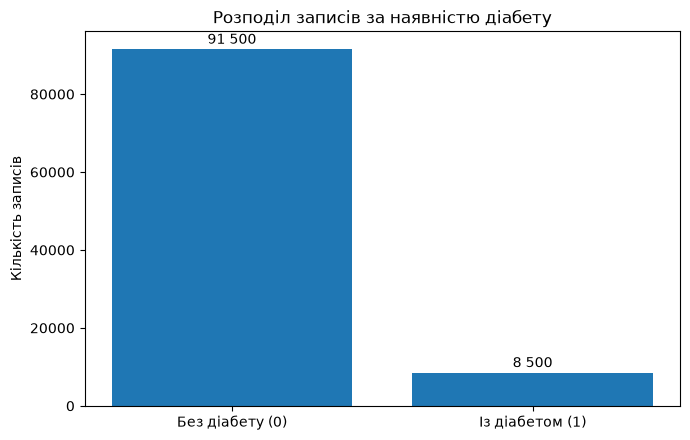

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(['Без діабету (0)', 'Із діабетом (1)'], [class_counts.get(0, 0), class_counts.get(1, 0)])
ax.set(title='Розподіл записів за наявністю діабету', ylabel='Кількість записів')
for bar in bars:
    h = bar.get_height()
    ax.annotate(f'{int(h):,}'.replace(',', ' '), (bar.get_x() + bar.get_width()/2, h), xytext=(0, 4), textcoords='offset points', ha='center')
fig.tight_layout()
fig.savefig(FIGURES / '01_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Розподіл числових ознак

Гістограми показують розподіл значень у наборі даних. Вони не встановлюють причин розвитку захворювання.

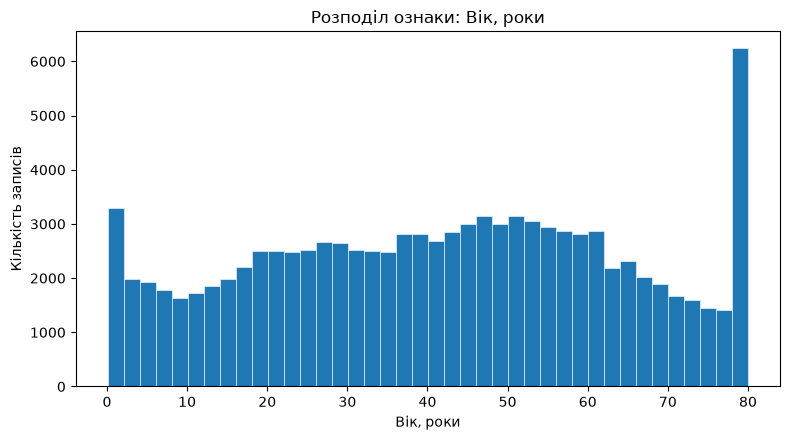

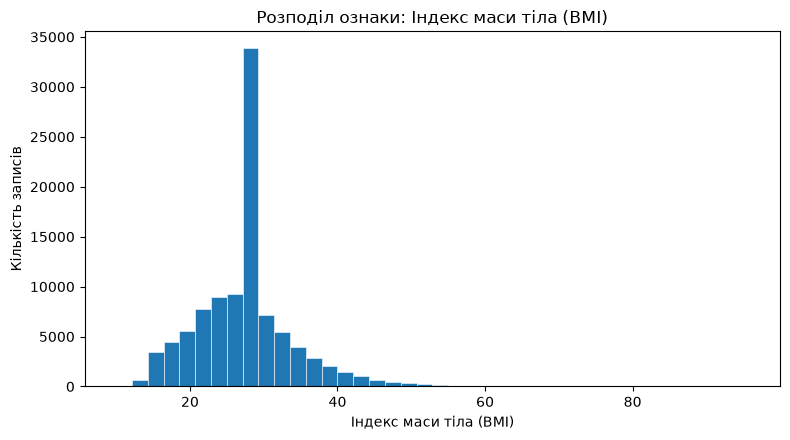

In [5]:
for feature, label, filename in [
    ('age', 'Вік, роки', '02_age_distribution.png'),
    ('bmi', 'Індекс маси тіла (BMI)', '03_bmi_distribution.png'),
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(df[feature].dropna(), bins=40, edgecolor='white', linewidth=0.4)
    ax.set(title=f'Розподіл ознаки: {label}', xlabel=label, ylabel='Кількість записів')
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches='tight')
    plt.show()

## 4. Лабораторні показники за класами

Порівнюємо розподіли HbA1c і глюкози за міткою `diabetes`. Ці показники можуть бути тісно пов’язані з критеріями встановлення мітки, тому висока роздільна здатність не підтверджує прогнозування майбутнього захворювання.

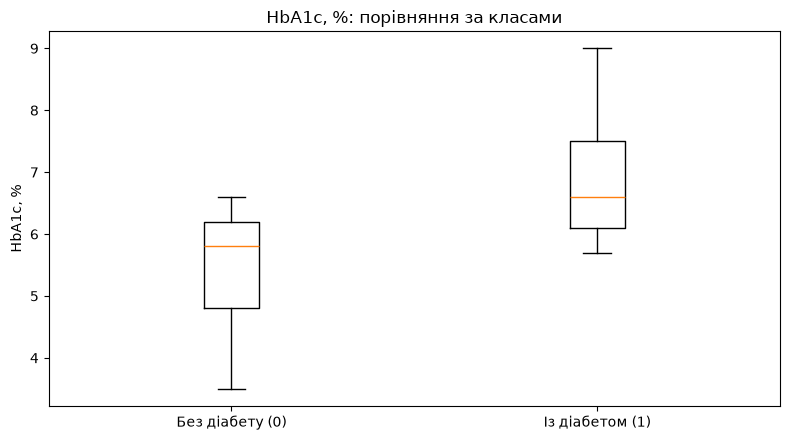

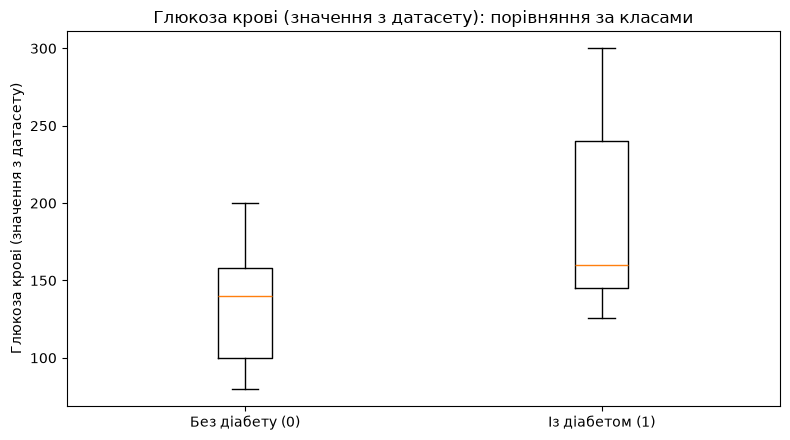

age                  bmi              HbA1c_level               \
           mean median    std   mean median   std        mean median   std   
diabetes                                                                     
0         40.12   40.0  22.31  26.89  27.32  6.37        5.40    5.8  0.97   
1         60.95   62.0  14.55  31.99  29.97  7.56        6.93    6.6  1.08   

         blood_glucose_level                
                        mean median    std  
diabetes                                    
0                     132.85  140.0  34.25  
1                     194.09  160.0  58.64

In [6]:
for feature, label, filename in [
    ('HbA1c_level', 'HbA1c, %', '04_hba1c_by_class.png'),
    ('blood_glucose_level', 'Глюкоза крові (значення з датасету)', '05_glucose_by_class.png'),
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    a = df.loc[df['diabetes'].eq(0), feature].dropna()
    b = df.loc[df['diabetes'].eq(1), feature].dropna()
    ax.boxplot([a, b], tick_labels=['Без діабету (0)', 'Із діабетом (1)'], showfliers=False)
    ax.set(title=f'{label}: порівняння за класами', ylabel=label)
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches='tight')
    plt.show()

comparisons = df.groupby('diabetes')[['age','bmi','HbA1c_level','blood_glucose_level']].agg(['mean','median','std']).round(2)
display(comparisons)
comparisons.to_csv(TABLES / '03_feature_stats_by_class.csv', encoding='utf-8-sig')

## 5. Частка позитивного класу за віковими групами

Це **спостережувана частка позитивних міток у вибірці**, а не оцінка поширеності діабету серед населення.

,Вікова група,Кількість записів,Позитивних міток,"Частка позитивних, %"
0,0–17,17219,82,0.48
1,18–29,15216,192,1.26
2,30–44,19973,833,4.17
3,45–59,22537,2461,10.92
4,60–80,25055,4932,19.68


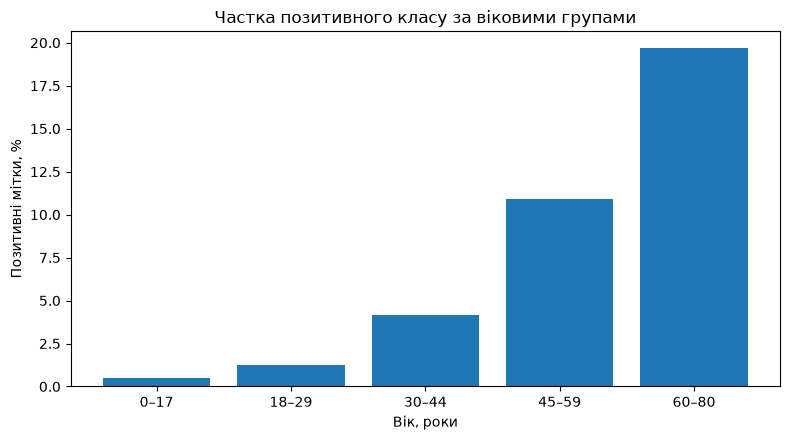

In [7]:
bins = [0, 18, 30, 45, 60, 81]
labels = ['0–17', '18–29', '30–44', '45–59', '60–80']
age_group = pd.cut(df['age'], bins=bins, labels=labels, right=False, include_lowest=True)
age_stats = df.groupby(age_group, observed=True)['diabetes'].agg(['size', 'sum', 'mean']).reset_index()
age_stats.columns = ['Вікова група', 'Кількість записів', 'Позитивних міток', 'Частка позитивних, %']
age_stats['Частка позитивних, %'] = (age_stats['Частка позитивних, %'] * 100).round(2)
display(age_stats)
age_stats.to_csv(TABLES / '04_age_groups.csv', index=False, encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(age_stats['Вікова група'].astype(str), age_stats['Частка позитивних, %'])
ax.set(title='Частка позитивного класу за віковими групами', xlabel='Вік, роки', ylabel='Позитивні мітки, %')
fig.tight_layout()
fig.savefig(FIGURES / '06_age_group_diabetes_rate.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Кореляційна матриця

Кореляція Пірсона відображає лінійні зв’язки числових стовпців і не означає причинно-наслідковий зв’язок. Бінарні змінні включені до матриці лише як числові коди; категоріальні текстові ознаки до неї не входять.

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
age,1.000,0.251,0.233,0.337,0.101,0.111,0.258
hypertension,0.251,1.000,0.121,0.148,0.081,0.084,0.198
heart_disease,0.233,0.121,1.000,0.061,0.068,0.070,0.172
bmi,0.337,0.148,0.061,1.000,0.083,0.091,0.214
HbA1c_level,0.101,0.081,0.068,0.083,1.000,0.167,0.401
blood_glucose_level,0.111,0.084,0.070,0.091,0.167,1.000,0.420
diabetes,0.258,0.198,0.172,0.214,0.401,0.420,1.000


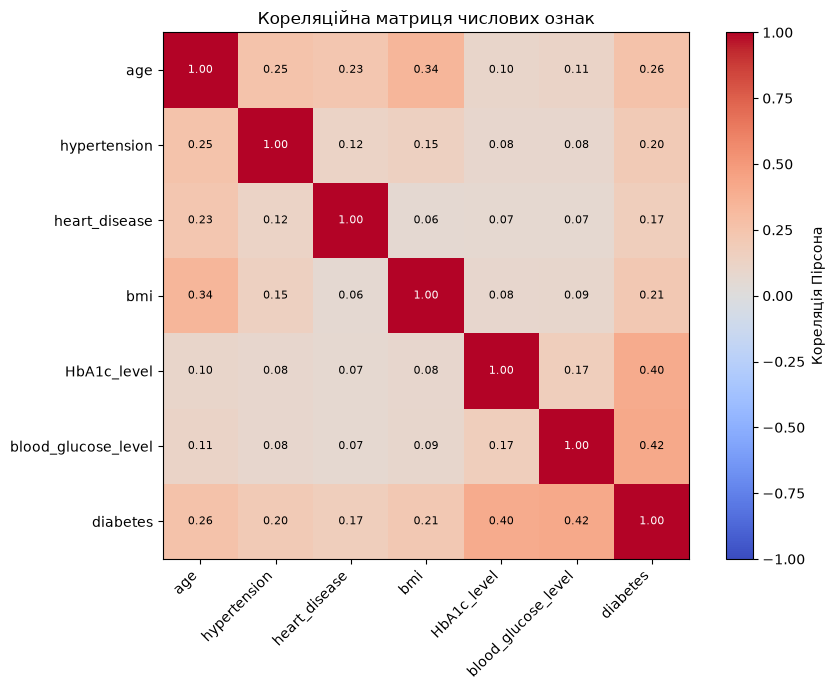

In [8]:
numeric = df.select_dtypes(include='number')
corr = numeric.corr()
display(corr.round(3))
corr.round(4).to_csv(TABLES / '05_numeric_correlations.csv', encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8, color=('white' if abs(corr.iloc[i,j]) > .65 else 'black'))
fig.colorbar(image, ax=ax, label='Кореляція Пірсона')
ax.set_title('Кореляційна матриця числових ознак')
fig.tight_layout()
fig.savefig(FIGURES / '07_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Контроль завершення EDA

Після запуску всіх комірок перевір, що папка `results/figures` містить 7 PNG, а `results/tables` — 5 CSV. Для пояснювальної записки слід описувати фактично отримані закономірності та обмеження вибірки.

**Що далі (лише після узгодження):** визначимо політику щодо дублікатів, побудуємо стратифіковане розбиття, використаємо `Pipeline` для підготовки ознак та навчимо базові моделі. Тестові дані не використовуватимемо для налаштування.

In [9]:
print('Графіків:', len(list(FIGURES.glob('*.png'))))
print('Таблиць:', len(list(TABLES.glob('*.csv'))))
print('Готово. Результати у папці:', ROOT / 'results')

Графіків: 7
Таблиць: 5
Готово. Результати у папці: /Users/glebsavelev/Desktop/da/results
